In [1]:
!pip install numpy==1.26.4
import os
os.environ["OMP_NUM_THREADS"]="1"
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans,DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from scipy.cluster.hierarchy import linkage, dendrogram
print("success")

success


In [2]:
df=pd.read_csv("Finance_Trends.csv")
print("success")

success


In [3]:
df=df.dropna()

In [4]:
#Risk Apetite Score (assigning more weight to risky investments)
df["Risk_Apetite"]=(df["Equity_Market"]*0.5+df["Mutual_Funds"]*0.5)

In [5]:
#Stability Index (safe investments)
df["Stability Index"]=(df["Fixed_Deposits"]*0.5+df["PPF"]*0.5)

In [6]:
#Diversification Index (Count of different investments, Ability to adopt to different nature of investments)
df[['Equity_Market','Mutual_Funds','Fixed_Deposits','PPF']] = df[
    ['Equity_Market','Mutual_Funds','Fixed_Deposits','PPF']
].apply(pd.to_numeric, errors='coerce')

df['Diversification_Index'] = ((df[['Equity_Market','Mutual_Funds','Fixed_Deposits','PPF']] >=3).sum(axis=1)
)

In [7]:
#Monitoring Frequency (How often do they check Investments)
df["Monitoring_Frequency"]= df["Invest_Monitor"].astype(str).str.strip().str.capitalize()
df["Monitoring_Frequency"]= df["Invest_Monitor"].map({"Daily":3,
                                                      "Weekly":2,
                                                      "Monthly":1})
df=df.dropna()
print("success")

success


In [8]:
df.rename(columns={"Stability Index":"Stability_Index"}, inplace=True)

In [9]:
#Feature Engineering Outcomes 
features=df[['Risk_Apetite','Stability_Index','Diversification_Index','Monitoring_Frequency']]

#Normalisation
scaler=MinMaxScaler()
scaled_features=scaler.fit_transform(features)

In [10]:
kmeans=KMeans(n_clusters=3, n_init=10, algorithm="lloyd")
df['KMeans_Cluster']=kmeans.fit_predict(scaled_features)

In [11]:
cluster_summary = df.groupby('KMeans_Cluster')[[
    'Risk_Apetite',
    'Stability_Index',
    'Diversification_Index',
    'Monitoring_Frequency'
]].head()

print(cluster_summary)

    Risk_Apetite  Stability_Index  Diversification_Index  Monitoring_Frequency
0            3.0              2.0                      2                     2
1            2.5              2.5                      2                     2
2            2.5              2.5                      2                     3
3            2.5              3.5                      2                     1
4            3.0              2.0                      2                     2
5            3.0              2.0                      2                     2
6            2.5              3.0                      2                     3
8            3.0              2.0                      2                     3
14           4.5              3.0                      3                     3
16           3.5              5.5                      4                     1
18           4.5              4.0                      3                     2
19           4.5              1.5                   

In [12]:
#DB Sacn clustering
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.8, min_samples=3)
df['DBSCAN_CLUSTER'] = dbscan.fit_predict(scaled_features)

In [13]:
cluster_summary = df.groupby('DBSCAN_CLUSTER')[[
    'Risk_Apetite',
    'Stability_Index',
    'Diversification_Index',
    'Monitoring_Frequency'
]].mean()

print(cluster_summary)

                Risk_Apetite  Stability_Index  Diversification_Index  \
DBSCAN_CLUSTER                                                         
0                   2.996792         2.789958               2.190167   

                Monitoring_Frequency  
DBSCAN_CLUSTER                        
0                            2.00275  


In [14]:
#evaluation (silhouette score)
kmeans_score=silhouette_score(scaled_features,df['KMeans_Cluster'])
print("K-Means Silhouette Score:",kmeans_score)

K-Means Silhouette Score: 0.46946648623876763


In [15]:
#DBSCAN SCORE(ONY IF MORE THAN ONE CLUSTER EXISTS)
labels = df['DBSCAN_CLUSTER']
unique_clusters = set(labels) - {-1}  

if len(unique_clusters) > 1:
    score = silhouette_score(scaled_features, labels)
    print("\nDBSCAN Silhouette Score:", score)
else:
    print("\nDBSCAN did not form meaningful clusters")


DBSCAN did not form meaningful clusters


In [16]:
#Decision Tree (Comparison)
X=scaled_features
y=df['KMeans_Cluster']

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.5)
dt=DecisionTreeClassifier()
dt.fit(X_train,y_train)

print("Decision Tree Accuracy")
dt.score(X_test,y_test)

Decision Tree Accuracy


1.0

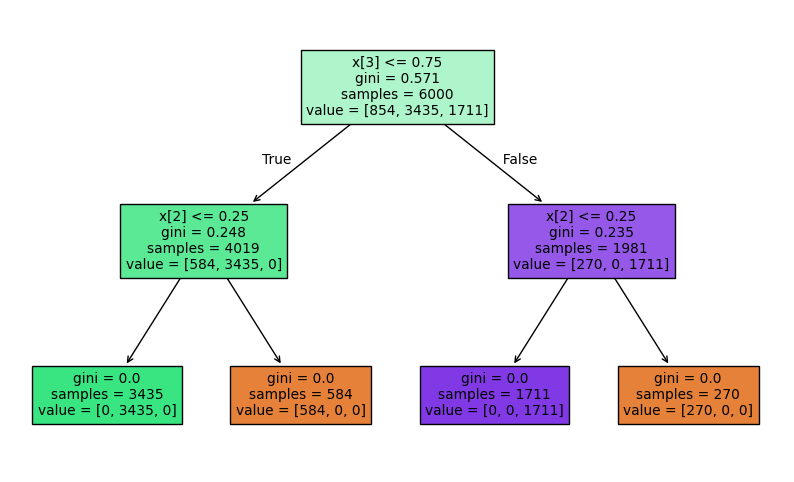

In [17]:
from sklearn.tree import plot_tree
plt.figure(figsize=(10,6))
plot_tree(dt, filled=True)
plt.show()

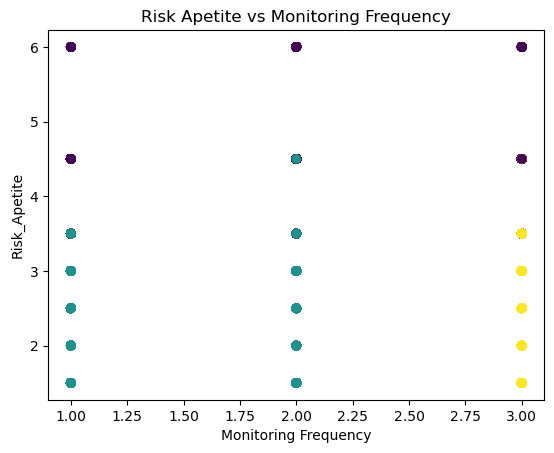

In [18]:
#Visualizations 
#K-Means plot 
plt.figure()
plt.scatter(df['Monitoring_Frequency'],df['Risk_Apetite'], c=df['KMeans_Cluster'])
plt.xlabel("Monitoring Frequency")
plt.ylabel("Risk_Apetite")
plt.title("Risk Apetite vs Monitoring Frequency")
plt.show()


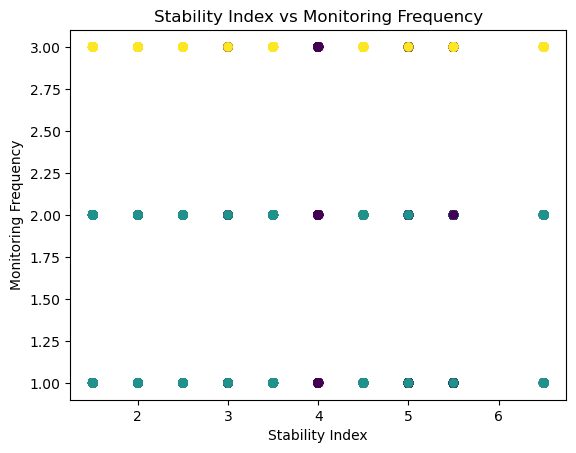

In [19]:
plt.figure()
plt.scatter(df['Stability_Index'],df['Monitoring_Frequency'], c=df['KMeans_Cluster'])
plt.xlabel("Stability Index")
plt.ylabel("Monitoring Frequency")
plt.title("Stability Index vs Monitoring Frequency")
plt.show()


In [20]:
#The scatter plots show that there is no clear linear relationship between Monitoring Frequency and Risk Appetite or Stability Index.
#Although monitoring levels are categorized as low, medium, and high, the data points are widely distributed across these levels.
#This indicates that investor behaviour is not linearly dependent on monitoring frequency and is influenced by multiple factors,
#making the relationship complex and non-linear.

In [21]:
#Cluster Interpretation 
cluster_summary = df.groupby('KMeans_Cluster')[[
    'Risk_Apetite',
    'Stability_Index',
    'Diversification_Index',
    'Monitoring_Frequency'
]].mean()

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
normalized = pd.DataFrame(
    scaler.fit_transform(cluster_summary),
    columns=cluster_summary.columns,
    index=cluster_summary.index
)

normalized['Risk_Score'] = (
    normalized['Risk_Apetite'] * 0.4
    - normalized['Stability_Index'] * 0.3
    - normalized['Diversification_Index'] * 0.2
    - normalized["Monitoring_Frequency"]* 0.2
)

high_risk_cluster = normalized['Risk_Score'].idxmax()
low_risk_cluster = normalized['Risk_Score'].idxmin()
moderate_cluster = list(set(normalized.index) - 
                        {high_risk_cluster, low_risk_cluster})[0]

df['Risk_Category'] = df['KMeans_Cluster'].map({
    high_risk_cluster: "High Risk",
    moderate_cluster: "Moderate Risk",
    low_risk_cluster: "Low Risk"
})

In [22]:
df["Risk_Category"]=df["KMeans_Cluster"].map({0:"Low Risk",1:"Moderate Risk",2:"High Risk"})

In [23]:
print(df[["Risk_Apetite","Stability_Index","Diversification_Index","Monitoring_Frequency","Risk_Category"]].head().tail())

   Risk_Apetite  Stability_Index  Diversification_Index  Monitoring_Frequency  \
0           3.0              2.0                      2                     2   
1           2.5              2.5                      2                     2   
2           2.5              2.5                      2                     3   
3           2.5              3.5                      2                     1   
4           3.0              2.0                      2                     2   

   Risk_Category  
0  Moderate Risk  
1  Moderate Risk  
2      High Risk  
3  Moderate Risk  
4  Moderate Risk  


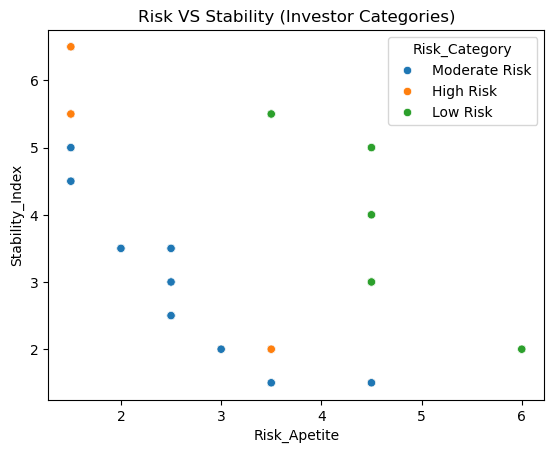

In [24]:
#Final Visualizations 
import seaborn as sns
sns.scatterplot(
    x="Risk_Apetite",
    y="Stability_Index",
    hue="Risk_Category",
    data=df)
plt.title("Risk VS Stability (Investor Categories)")
plt.show()

In [25]:
#Diversification behaviour vs risk apetite

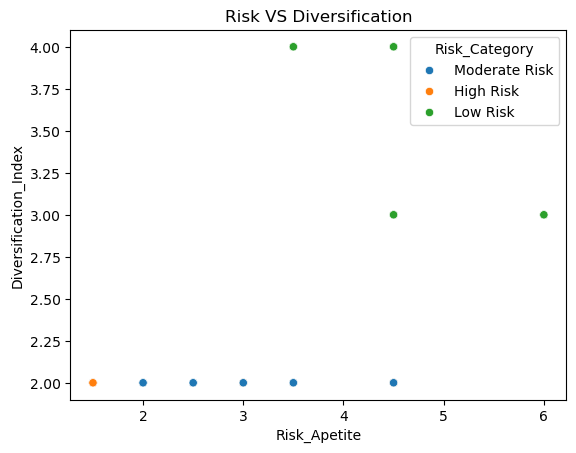

In [26]:
sns.scatterplot(
    x="Risk_Apetite",
    y="Diversification_Index",
    hue="Risk_Category",
    data=df)
plt.title("Risk VS Diversification")
plt.show()

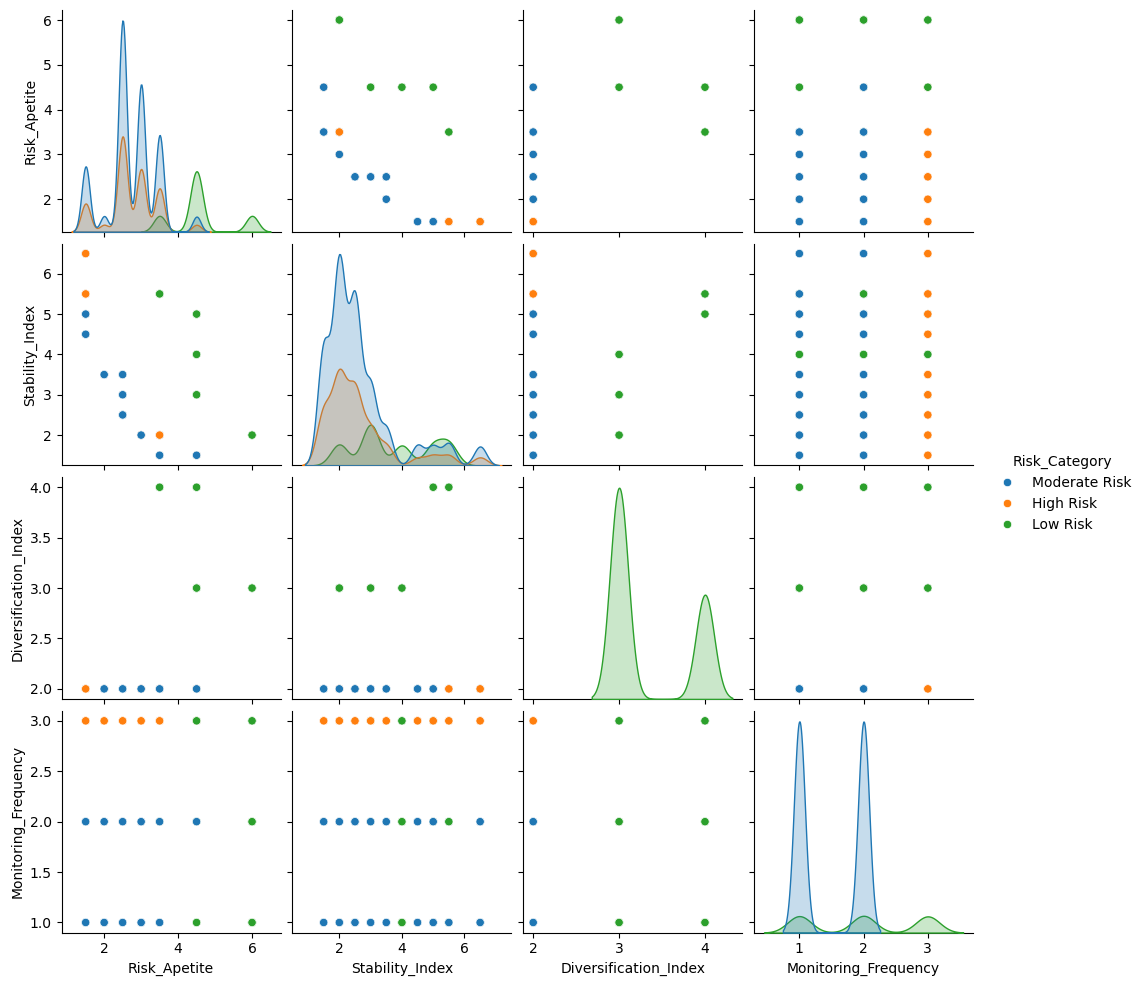

In [27]:
#Pair plot 
sns.pairplot(
    df,
    vars=[
        "Risk_Apetite",
        "Stability_Index",
        "Diversification_Index",
        "Monitoring_Frequency"
    ],
    hue="Risk_Category")
plt.show()

In [28]:
#Clustering Relationship with Investment Purpose 
pd.crosstab(df["KMeans_Cluster"],df["Purpose"])

Purpose,Returns,Savings for Future,Wealth Creation
KMeans_Cluster,,,
0,280,0,1435
1,188,1210,5430
2,97,611,2749


In [29]:
# Cluster 0= The group of people who invest to make money and not rely on savings
# Cluster 1= Very high wealth creation but aslo relies on savings
# Cluster 2= lower intensity, more cautious 

In [30]:
#Investment Purpose with risk categories 
pd.crosstab(df["Risk_Category"],df["Purpose"])

Purpose,Returns,Savings for Future,Wealth Creation
Risk_Category,,,
High Risk,97,611,2749
Low Risk,280,0,1435
Moderate Risk,188,1210,5430


In [31]:
df["Purpose"]=df["Purpose"].astype(str)
df["Risk_Category"]=df["Risk_Category"].astype(str)

<function matplotlib.pyplot.show(close=None, block=None)>

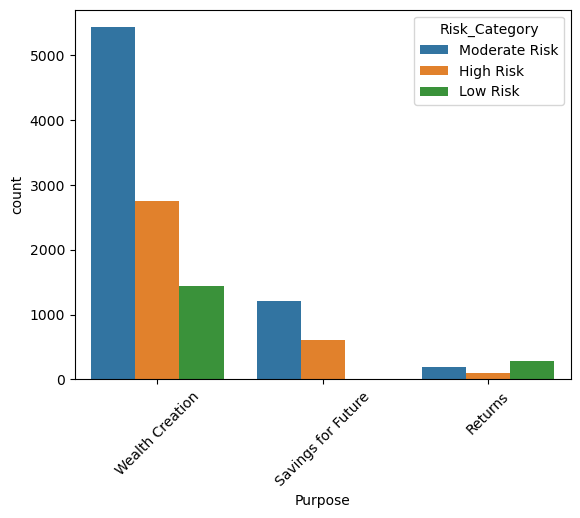

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.countplot(
    data=df,
    x="Purpose",
    hue="Risk_Category"
)
plt.xticks(rotation=45)
plt.show

In [33]:
pd.crosstab(df["gender"],df["Risk_Category"])

Risk_Category,High Risk,Low Risk,Moderate Risk
gender,,,
Female,1079,1144,2286
Male,2378,571,4542


In [34]:
bins=[18,22,26,30,35]
labels=["18-21","22-25","26-30","31-35"]

df["Age_Group"]=pd.cut(df["age"],bins=bins, labels=labels)

In [35]:
pd.crosstab(df["Age_Group"],df["Risk_Category"])

Risk_Category,High Risk,Low Risk,Moderate Risk
Age_Group,,,
18-21,304,227,522
22-25,962,565,1950
26-30,1291,517,2569
31-35,750,325,1512


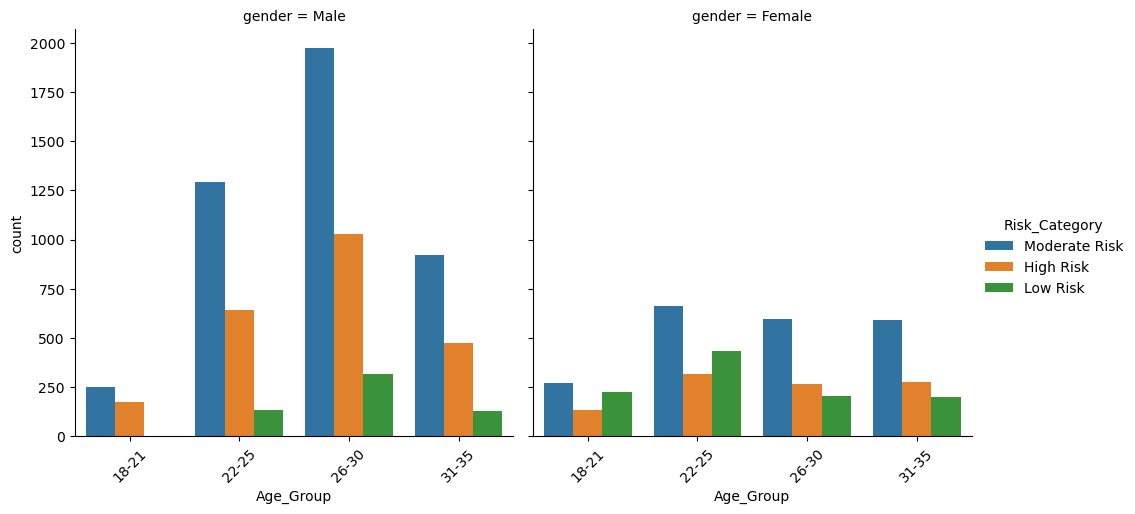

In [36]:
import seaborn as sns
import matplotlib.pyplot as plt
g=sns.catplot(
    data=df,
    x="Age_Group",
    hue="Risk_Category",
    col="gender",
    kind="count"
)
g.set_xticklabels(rotation=45)
plt.show()

In [37]:
pd.crosstab(df["Source"],df["Risk_Category"])

Risk_Category,High Risk,Low Risk,Moderate Risk
Source,,,
Financial Consultants,1392,569,2815
Internet,308,295,617
Newspapers and Magazines,1327,280,2556
Television,430,571,840


In [38]:
pd.crosstab(df["Reason_Bonds"],df["Risk_Category"])

Risk_Category,High Risk,Low Risk,Moderate Risk
Reason_Bonds,,,
Assured Returns,2450,573,4860
Safe Investment,897,1142,1776
Tax Incentives,110,0,192


In [39]:
risk_counts=df['Risk_Category'].value_counts()
risk_counts

Risk_Category
Moderate Risk    6828
High Risk        3457
Low Risk         1715
Name: count, dtype: int64

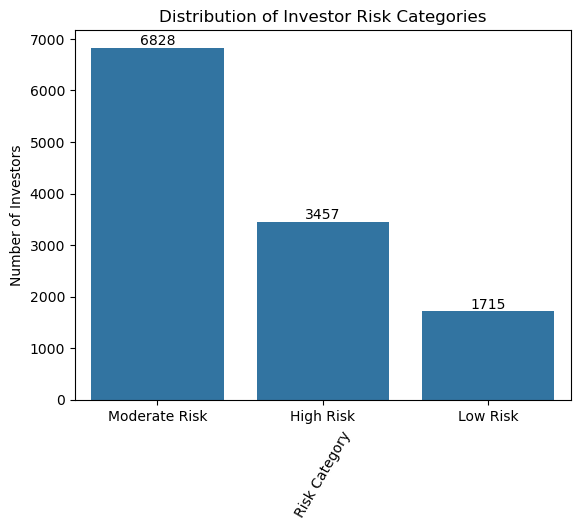

In [40]:
import seaborn as sns
import matplotlib.pyplot as plt

ax = sns.countplot(
    data=df,
    x='Risk_Category'
)
for container in ax.containers:
    ax.bar_label(container)

plt.title("Distribution of Investor Risk Categories")
plt.xlabel("Risk Category",rotation =60)
plt.ylabel("Number of Investors")

plt.show()

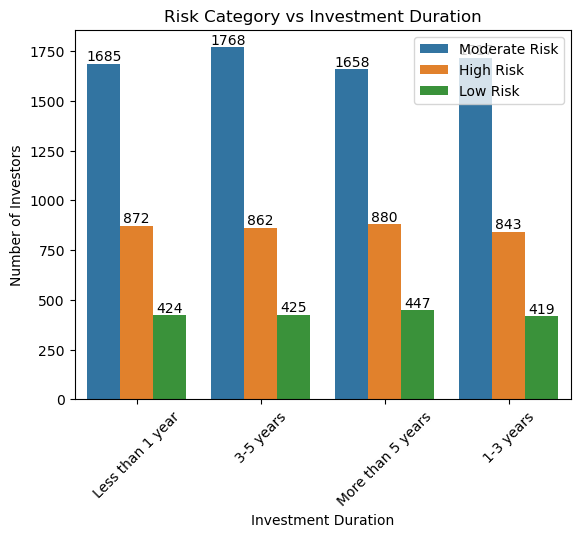

In [41]:
import seaborn as sns
import matplotlib.pyplot as plt

ax = sns.countplot(
    data=df,
    x='Duration',
    hue="Risk_Category"
)
for container in ax.containers:
    ax.bar_label(container)

plt.title("Risk Category vs Investment Duration")
plt.xlabel("Investment Duration")
plt.ylabel("Number of Investors")

plt.xticks(rotation=45)
plt.legend()

plt.show()

In [42]:
normal_risk = df['Risk_Apetite'].median()

normal_stability = df['Stability_Index'].median()

normal_diversification = df['Diversification_Index'].median()

normal_monitoring = df['Monitoring_Frequency'].median()

In [43]:
def get_recommendation(row):

    recommendations = []

    if row['Risk_Apetite'] > normal_risk:
        recommendations.append(
            "Reduce excessive risk exposure and maintain portfolio balance."
        )

    if row['Stability_Index'] < normal_stability:
        recommendations.append(
            "Include more stable investment instruments."
        )

    if row['Diversification_Index'] < normal_diversification:
        recommendations.append(
            "Increase portfolio diversification."
        )

    if row['Monitoring_Frequency'] < normal_monitoring:
        recommendations.append(
            "Monitor investments more frequently."
        )

    if len(recommendations) == 0:
        recommendations.append(
        "Current investment behaviour is well-balanced. Continue maintaining the existing investment strategy while periodically reviewing financial goals.")

    return " | ".join(recommendations)

In [44]:
df['Recommendation'] = df.apply(get_recommendation, axis=1)

In [102]:
df[['Risk_Category',
    'Risk_Apetite',
    'Stability_Index',
    'Diversification_Index',
    'Monitoring_Frequency',
    'Recommendation']].head(10)

,Risk_Category,Risk_Apetite,Stability_Index,Diversification_Index,Monitoring_Frequency,Recommendation
0,Moderate Risk,3.0,2.0,2,2,Include more stable investment instruments.
1,Moderate Risk,2.5,2.5,2,2,Current investment behaviour is well-balanced....
2,High Risk,2.5,2.5,2,3,Current investment behaviour is well-balanced....
3,Moderate Risk,2.5,3.5,2,1,Monitor investments more frequently.
4,Moderate Risk,3.0,2.0,2,2,Include more stable investment instruments.
5,Moderate Risk,3.0,2.0,2,2,Include more stable investment instruments.
6,High Risk,2.5,3.0,2,3,Current investment behaviour is well-balanced....
7,Moderate Risk,3.5,1.5,2,2,Reduce excessive risk exposure and maintain po...
8,High Risk,3.0,2.0,2,3,Include more stable investment instruments.
9,Moderate Risk,3.0,2.0,2,1,Include more stable investment instruments. | ...


In [46]:
df['Recommendation'].value_counts()

Recommendation
Current investment behaviour is well-balanced. Continue maintaining the existing investment strategy while periodically reviewing financial goals.     3664
Monitor investments more frequently.                                                                                                                   1808
Include more stable investment instruments.                                                                                                            1777
Reduce excessive risk exposure and maintain portfolio balance. | Include more stable investment instruments.                                           1625
Reduce excessive risk exposure and maintain portfolio balance.                                                                                          948
Include more stable investment instruments. | Monitor investments more frequently.                                                                      938
Reduce excessive risk exposure and maintain portf

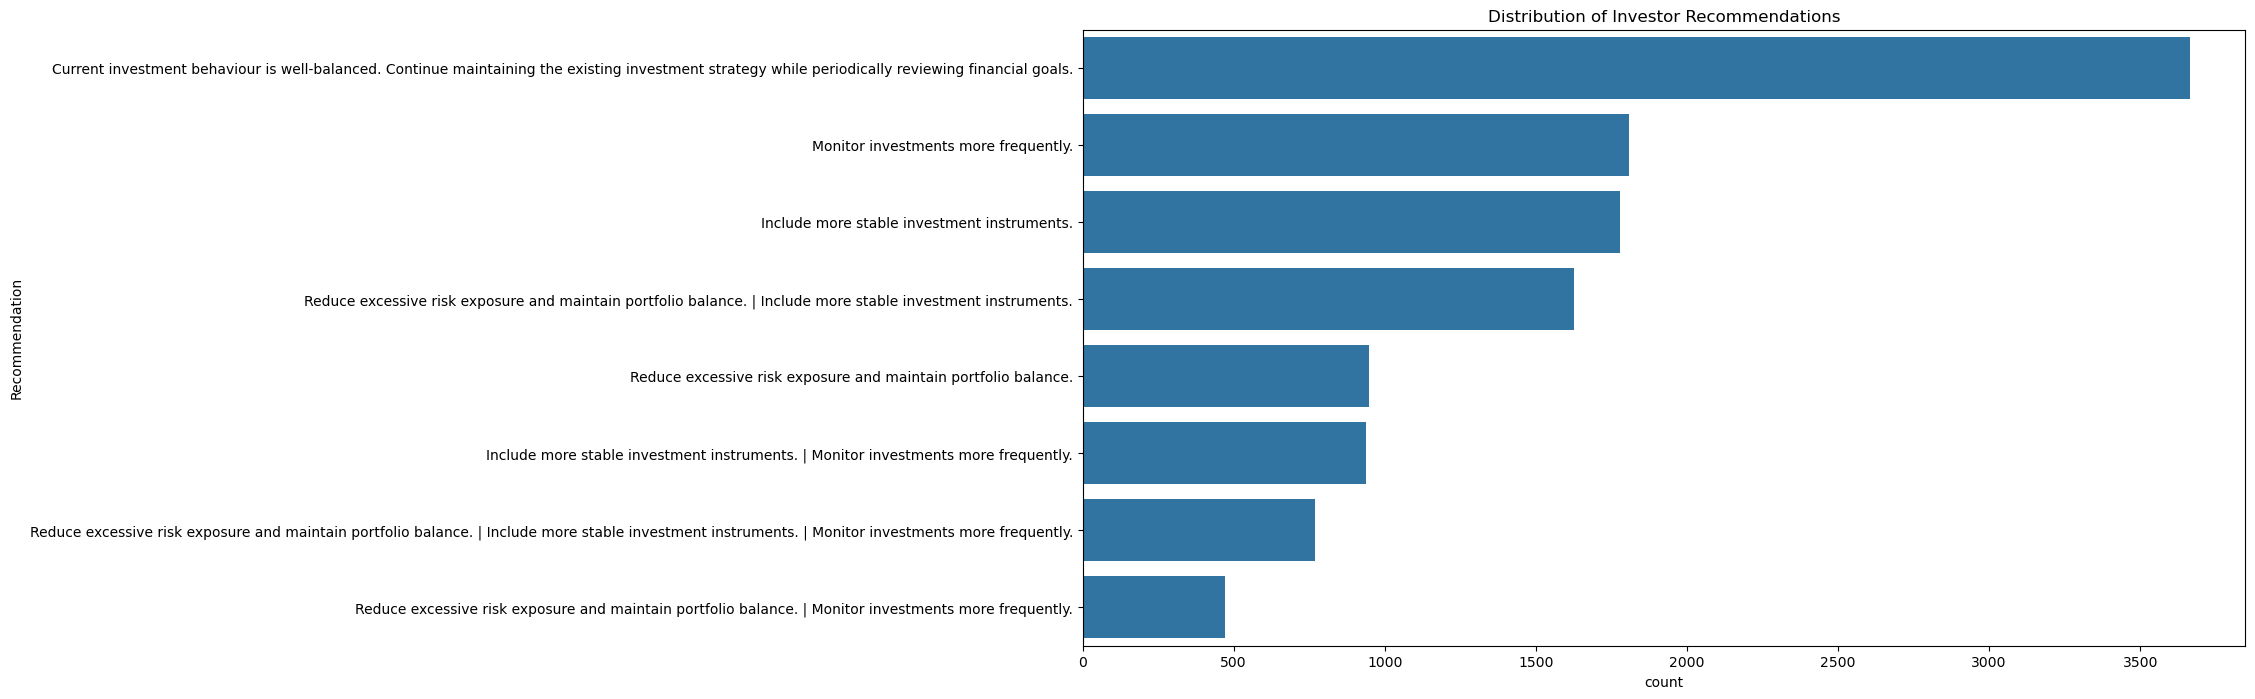

In [47]:
plt.figure(figsize=(15,8))

sns.countplot(
    y='Recommendation',
    data=df,
    order=df['Recommendation'].value_counts().index
)

plt.title("Distribution of Investor Recommendations")
plt.show()

In [48]:
pd.crosstab(
    df['Risk_Category'],
    df['Recommendation']
)

Recommendation,Current investment behaviour is well-balanced. Continue maintaining the existing investment strategy while periodically reviewing financial goals.,Include more stable investment instruments.,Include more stable investment instruments. | Monitor investments more frequently.,Monitor investments more frequently.,Reduce excessive risk exposure and maintain portfolio balance.,Reduce excessive risk exposure and maintain portfolio balance. | Include more stable investment instruments.,Reduce excessive risk exposure and maintain portfolio balance. | Include more stable investment instruments. | Monitor investments more frequently.,Reduce excessive risk exposure and maintain portfolio balance. | Monitor investments more frequently.
Risk_Category,,,,,,,,
High Risk,1853,890,0,0,0,714,0,0
Low Risk,0,0,0,0,948,196,99,472
Moderate Risk,1811,887,938,1808,0,715,669,0
